In [ ]:
import zipfile
zip = zipfile.ZipFile('/content/drive/MyDrive/fruit_vegetables_CNN(4-0ct-26)/Fruits_Vegetables.zip')

In [ ]:
zip.extractall("Fruits_Vegetables.zip")

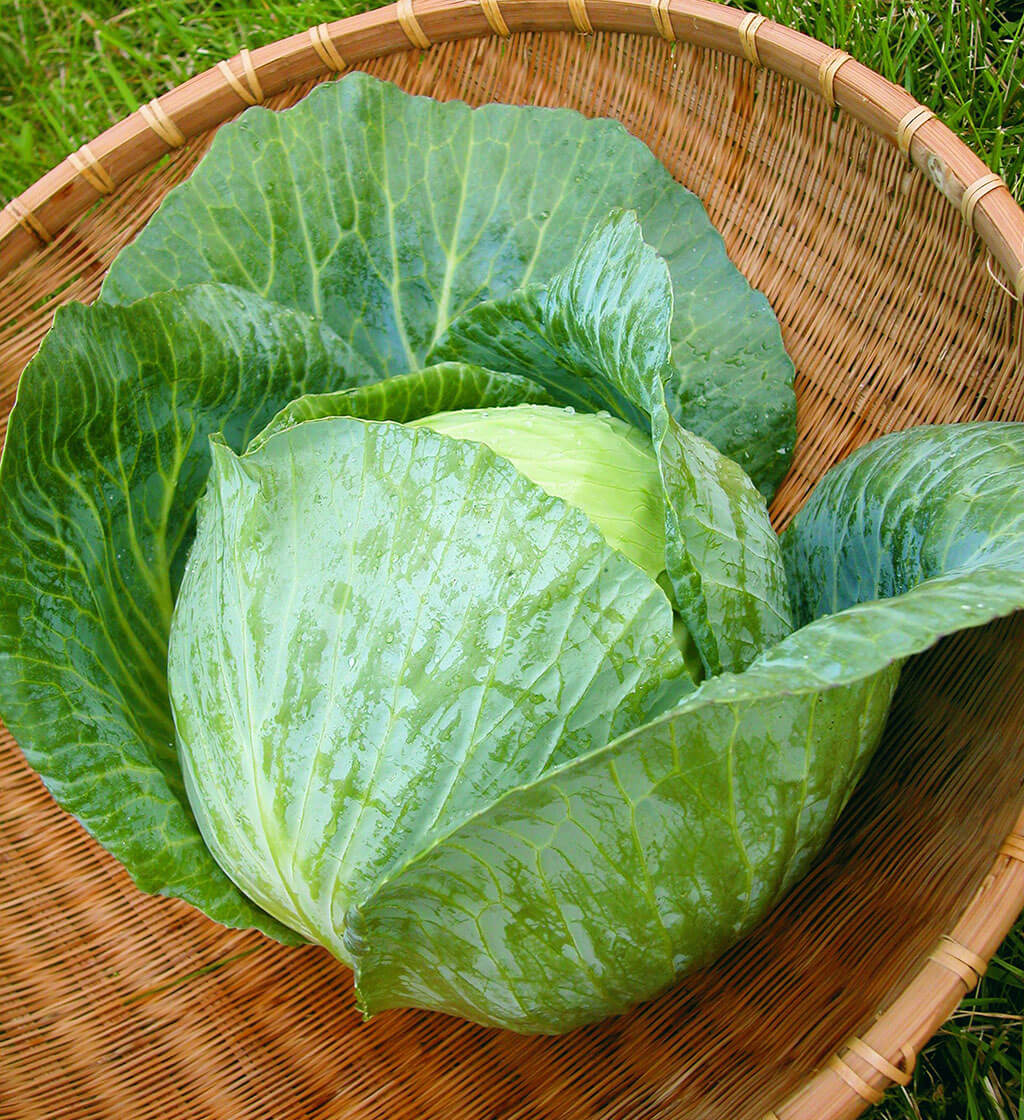

In [ ]:
from PIL import Image
Image.open('/content/Fruits_Vegetables.zip/Fruits_Vegetables/test/cabbage/Image_1.jpg')

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import  layers
from tensorflow.keras.models import Sequential

In [ ]:
img_height = 180
img_weidth = 180

In [ ]:
train_images = tf.keras.utils.image_dataset_from_directory(
    '/content/Fruits_Vegetables.zip/Fruits_Vegetables/train',
    seed=42,
    image_size=(img_height, img_weidth),
    batch_size=32,
    shuffle = True,
    validation_split=False,
)

Found 3115 files belonging to 36 classes.


In [ ]:
data_labels = train_images.class_names

In [ ]:
test_images = tf.keras.utils.image_dataset_from_directory(
    '/content/Fruits_Vegetables.zip/Fruits_Vegetables/test',
    seed=42,
    image_size=(img_height, img_weidth),
    batch_size=32,
    shuffle = True,
    validation_split=False,
)

Found 359 files belonging to 36 classes.


In [ ]:
Val_images = tf.keras.utils.image_dataset_from_directory(
    '/content/Fruits_Vegetables.zip/Fruits_Vegetables/validation',
    seed=42,
    image_size=(img_height, img_weidth),
    batch_size=32,
    shuffle = True,
    validation_split=False,
)

Found 351 files belonging to 36 classes.


In [ ]:
model = Sequential([
    layers.Rescaling(.1/255),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(data_labels))
])

In [ ]:
model.compile(optimizer = "adam",loss= tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])

In [ ]:
history = model.fit(train_images, validation_data=Val_images, epochs=10,batch_size=32)

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 723ms/step - accuracy: 0.0421 - loss: 3.5002 - val_accuracy: 0.1168 - val_loss: 3.1720
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 59s 605ms/step - accuracy: 0.1612 - loss: 2.9459 - val_accuracy: 0.3504 - val_loss: 2.2639
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 82s 608ms/step - accuracy: 0.3018 - loss: 2.3851 - val_accuracy: 0.4217 - val_loss: 1.9589
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 62s 631ms/step - accuracy: 0.3846 - loss: 2.0983 - val_accuracy: 0.5954 - val_loss: 1.3864
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 60s 611ms/step - accuracy: 0.4501 - loss: 1.8457 - val_accuracy: 0.6353 - val_loss: 1.1709
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 617ms/step - accuracy: 0.5159 - loss: 1.6334 - val_accuracy: 0.6923 - val_loss: 1.0269
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 79s 595ms/step - accuracy: 0.5695 - loss: 1.4289 - val_accuracy: 0.7664 - val_loss: 0.7503
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 62s 636ms/step - accuracy: 0.6276 - loss: 1.2271 - val_accu

In [ ]:
img = "/content/Fruits_Vegetables.zip/Fruits_Vegetables/train/apple/Image_16.jpg"

In [ ]:
img = tf.keras .utils.load_img(img,target_size=(img_height,img_weidth))

In [ ]:
img_array = tf.keras.utils.img_to_array(img)
img = tf.expand_dims(img,0)

In [ ]:
import numpy as np
def predictor(img):
  image = img
  img = tf.keras.utils.load_img(img,target_size=(img_height,img_weidth))
  img_array = tf.keras.utils.img_to_array(img)
  img = tf.expand_dims(img_array,0)
  prediction = model.predict(img)
  score = tf.nn.softmax(prediction)
  return f"the provided images is an {data_labels[np.argmax(score)]},and model confidence is {np.max(score)*100}"

In [ ]:
predictor ("/content/Fruits_Vegetables.zip/Fruits_Vegetables/train/apple/Image_10.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step


'the provided images is an paprika,and model confidence is 38.74877166748047'

In [2]:
model.save("C:\\Users\\Lapzone.pk\\OneDrive\\Desktop\\AIDS\\CNN\\fruits & vegetables.h5")

NameError: name 'model' is not defined